# Peak Hour Prediction (Regresi Jam Ramai)

Tujuan: memprediksi jam-jam dengan aktivitas penjualan tertinggi.

- Input: `Time`, `Date`, `Outlet`, `TotalItem`, `NetSales`
- Target regresi: **NetSales per jam** untuk setiap outlet
- Model: tiga algoritma regresi, diambil yang terbaik
  **Ridge Regression**, **Random Forest**, **Gradient Boosting**
- Output: tabel prediksi NetSales tiap jam beserta peringkat jam tersibuk

Satuan analisis adalah **sel outlet x tanggal x jam**. Ada 3 outlet, 272 hari, dan 16 jam operasional,
sehingga terbentuk 13.056 baris. Jam yang tidak ada transaksinya tetap disimpan bernilai 0 karena
memang tutup, bukan data hilang.

Hasil disimpan di `artifacts/peak_hour/`.

## 1. Konfigurasi

In [1]:
import json
import pickle
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

DATA_PATH = Path("..") / "data" / "Transactions.csv"
OUTPUT_DIR = Path("..") / "artifacts" / "peak_hour"
MODEL_PATH = OUTPUT_DIR / "model.pkl"
METADATA_PATH = OUTPUT_DIR / "metadata.json"

TEST_DAYS = 28      # hari terakhir sebagai data uji
SEED = 42

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("pandas      :", pd.__version__)
print("folder hasil:", OUTPUT_DIR.resolve())

C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


pandas      : 3.0.3
folder hasil: C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\ML\artifacts\peak_hour


## 2. Memuat data dan mengambil jam

Kolom `Time` berformat `HH:MM:SS`. Hanya angka jamnya yang dipakai karena analisisnya per jam.

In [2]:
transactions = pd.read_csv(DATA_PATH, parse_dates=["Date"])

transactions["Hour"] = pd.to_datetime(transactions.Time, format="%H:%M:%S").dt.hour

print(f"baris transaksi : {len(transactions):,}")
print(f"outlet          : {sorted(transactions.Outlet.unique())}")
print(f"rentang tanggal : {transactions.Date.min().date()} s/d {transactions.Date.max().date()}")
print(f"jumlah hari     : {transactions.Date.nunique()}")
print(f"jam operasional : {sorted(transactions.Hour.unique())}")

baris transaksi : 53,820
outlet          : ['SHOP001', 'SHOP002', 'SHOP003']
rentang tanggal : 2025-01-02 s/d 2025-09-30
jumlah hari     : 272
jam operasional : [7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


## 3. Membentuk panel outlet x tanggal x jam

Grid lengkap dibuat supaya jam yang tutup tetap muncul bernilai nol. Tanpa langkah ini, jam tutup
akan terlihat seperti data hilang dan model bisa salah membaca polanya.

In [3]:
hourly = transactions.groupby(["Outlet", "Date", "Hour"]).agg(
    net_sales=("NetSales", "sum"),
    items=("TotalItem", "sum"),
    receipts=("ReceiptNumber", "nunique"),
).reset_index()

grid = pd.MultiIndex.from_product(
    [sorted(transactions.Outlet.unique()), sorted(transactions.Date.unique()), sorted(transactions.Hour.unique())],
    names=["Outlet", "Date", "Hour"],
)

panel = hourly.set_index(["Outlet", "Date", "Hour"]).reindex(grid).fillna(0).reset_index()
panel = panel.sort_values(["Outlet", "Hour", "Date"]).reset_index(drop=True)

print("bentuk panel:", panel.shape)
print(f"sel tanpa penjualan (jam tutup): {int((panel.net_sales == 0).sum()):,} "
      f"({(panel.net_sales == 0).mean():.1%})")
print()
print(panel.head(4).round(1).to_string(index=False))

bentuk panel: (13056, 6)
sel tanpa penjualan (jam tutup): 1,309 (10.0%)

 Outlet       Date  Hour  net_sales  items  receipts
SHOP001 2025-01-02     7    83783.8    4.0       4.0
SHOP001 2025-01-03     7    45945.9    2.0       2.0
SHOP001 2025-01-04     7   133333.3    6.0       5.0
SHOP001 2025-01-05     7   115315.3    7.0       6.0


## 4. Pola jam ramai

Sebelum memodelkan, dilihat dulu kapan penjualan memang memuncak. Ini menjadi acuan kebenaran
untuk menilai apakah model berhasil menemukan jam sibuk.

In [4]:
profile_overall = panel.groupby("Hour").net_sales.mean()
share_overall = panel.groupby("Hour").net_sales.sum() / panel.net_sales.sum() * 100

ringkasan_jam = pd.DataFrame({
    "rata_net_sales": profile_overall,
    "pangsa_omzet_%": share_overall,
    "rata_item": panel.groupby("Hour").items.mean(),
    "rata_struk": panel.groupby("Hour").receipts.mean(),
})
print("Profil per jam, seluruh outlet:")
print(ringkasan_jam.round(1).to_string())
print()
print("Tiga jam tertinggi:", profile_overall.nlargest(3).index.tolist())
print("Tiga jam terendah :", profile_overall.nsmallest(3).index.tolist())

Profil per jam, seluruh outlet:
      rata_net_sales  pangsa_omzet_%  rata_item  rata_struk
Hour                                                       
7            63176.8             4.4        3.3         2.8
8            62999.0             4.3        3.3         2.9
9            91073.8             6.3        4.7         4.1
10           85180.4             5.9        4.5         3.9
11           85762.2             5.9        4.5         3.9
12           86605.7             6.0        4.6         4.0
13           87968.1             6.1        4.6         4.0
14           82688.6             5.7        4.3         3.8
15           85646.3             5.9        4.4         3.9
16           88120.5             6.1        4.6         4.0
17          103770.3             7.1        5.5         4.8
18          103983.4             7.2        5.5         4.7
19          105671.5             7.3        5.5         4.8
20          108482.4             7.5        5.7         4.9
21      

In [5]:
jam_buka = panel.groupby(["Outlet", "Hour"]).net_sales.mean().unstack()
jam_buka = (jam_buka > 0).astype(int)

print("Jam buka per outlet (1 berarti ada penjualan):")
print(jam_buka.to_string())
print()
print("Rata-rata NetSales per outlet dan jam (ribu rupiah):")
print((panel.groupby(["Outlet", "Hour"]).net_sales.mean().unstack() / 1000).round(1).to_string())

Jam buka per outlet (1 berarti ada penjualan):
Hour     7   8   9   10  11  12  13  14  15  16  17  18  19  20  21  22
Outlet                                                                 
SHOP001   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1
SHOP002   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1
SHOP003   0   0   1   1   1   1   1   1   1   1   1   1   1   1   1   1

Rata-rata NetSales per outlet dan jam (ribu rupiah):
Hour        7      8      9      10     11     12     13     14     15     16     17     18     19     20     21     22
Outlet                                                                                                                 
SHOP001  134.0  136.3  130.1  113.2  122.3  119.2  120.0  117.7  119.9  118.7  149.4  151.8  148.9  154.2  145.3  152.3
SHOP002   55.5   52.7   54.6   48.9   48.4   47.7   50.9   47.0   48.4   48.2   59.7   58.8   60.4   60.3   60.6   64.8
SHOP003    0.0    0.0   88.5   93.4   86.6   92.9   93.0   

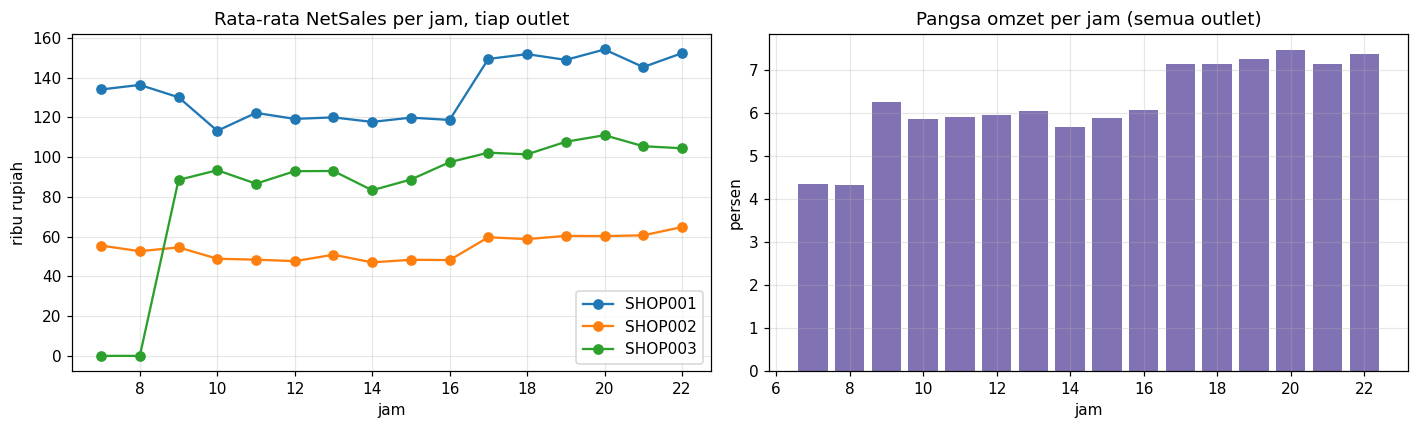

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for outlet in sorted(panel.Outlet.unique()):
    series = panel[panel.Outlet == outlet].groupby("Hour").net_sales.mean()
    axes[0].plot(series.index, series / 1000, marker="o", label=outlet)
axes[0].set_title("Rata-rata NetSales per jam, tiap outlet")
axes[0].set_xlabel("jam")
axes[0].set_ylabel("ribu rupiah")
axes[0].legend()

axes[1].bar(share_overall.index, share_overall.values, color="#8172b3")
axes[1].set_title("Pangsa omzet per jam (semua outlet)")
axes[1].set_xlabel("jam")
axes[1].set_ylabel("persen")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_1_hourly_profile.png", dpi=120)
plt.show()

## 5. Fitur model

Fitur disusun dari dua sumber yang sama-sama tersedia sebelum hari yang diprediksi:

1. **Kalender**: jam, hari dalam minggu, akhir pekan, bulan, hari ke-, serta bentuk siklus jam.
2. **Riwayat jam yang sama**: nilai jam tersebut kemarin, seminggu lalu, rata-rata 7 hari, dan rata-rata 28 hari.
3. **Rata-rata historis outlet x jam**, dihitung hanya dari data latih agar tidak bocor ke data uji.

In [7]:
panel["dow"] = panel.Date.dt.dayofweek
panel["is_weekend"] = (panel.dow >= 5).astype(int)
panel["month"] = panel.Date.dt.month
panel["day_of_year"] = panel.Date.dt.dayofyear
panel["hour_sin"] = np.sin(2 * np.pi * panel.Hour / 24)
panel["hour_cos"] = np.cos(2 * np.pi * panel.Hour / 24)
panel["outlet_code"] = panel.Outlet.str[-1].astype(int)

by_hour = panel.groupby(["Outlet", "Hour"])
panel["lag_1d"] = by_hour.net_sales.shift(1)
panel["lag_7d"] = by_hour.net_sales.shift(7)
panel["roll_7"] = by_hour.net_sales.transform(lambda series: series.shift(1).rolling(7).mean())
panel["roll_28"] = by_hour.net_sales.transform(lambda series: series.shift(1).rolling(28).mean())

cutoff = panel.Date.max() - pd.Timedelta(days=TEST_DAYS)
train_mask = panel.Date <= cutoff

outlet_hour_mean = panel[train_mask].groupby(["Outlet", "Hour"]).net_sales.mean().rename("outlet_hour_mean")
panel = panel.merge(outlet_hour_mean, on=["Outlet", "Hour"], how="left")

print("kolom panel sekarang:", list(panel.columns))
print(f"batas data latih: {panel.Date.min().date()} s/d {cutoff.date()}")
print(f"batas data uji  : {(cutoff + pd.Timedelta(days=1)).date()} s/d {panel.Date.max().date()}")

kolom panel sekarang: ['Outlet', 'Date', 'Hour', 'net_sales', 'items', 'receipts', 'dow', 'is_weekend', 'month', 'day_of_year', 'hour_sin', 'hour_cos', 'outlet_code', 'lag_1d', 'lag_7d', 'roll_7', 'roll_28', 'outlet_hour_mean']
batas data latih: 2025-01-02 s/d 2025-09-02
batas data uji  : 2025-09-03 s/d 2025-09-30


In [8]:
FEATURES = [
    "Hour",
    "dow",
    "is_weekend",
    "month",
    "day_of_year",
    "hour_sin",
    "hour_cos",
    "outlet_code",
    "outlet_hour_mean",
    "lag_1d",
    "lag_7d",
    "roll_7",
    "roll_28",
]

model_data = panel.dropna(subset=FEATURES).copy()

train = model_data[model_data.Date <= cutoff]
test = model_data[model_data.Date > cutoff]

X_train = train[FEATURES].to_numpy()
y_train = train.net_sales.to_numpy()
X_test = test[FEATURES].to_numpy()
y_test = test.net_sales.to_numpy()

print("bentuk data latih:", X_train.shape)
print("bentuk data uji  :", X_test.shape)
print(f"rata-rata NetSales latih: Rp {y_train.mean():,.0f} per jam-outlet")
print(f"rata-rata NetSales uji  : Rp {y_test.mean():,.0f} per jam-outlet")

bentuk data latih: (10368, 13)
bentuk data uji  : (1344, 13)
rata-rata NetSales latih: Rp 92,783 per jam-outlet
rata-rata NetSales uji  : Rp 84,325 per jam-outlet


## 6. Melatih tiga model regresi

Tiga algoritma dengan sifat berbeda: linier (Ridge), kumpulan pohon acak (Random Forest), dan
pohon boosted (Gradient Boosting).

In [9]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=10,
        random_state=SEED,
        n_jobs=1,
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=3,
        random_state=SEED,
    ),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name:<20} selesai dilatih")

Ridge                selesai dilatih


Random Forest        selesai dilatih


Gradient Boosting    selesai dilatih


## 7. Evaluasi

Dua kelompok ukuran dipakai karena tujuannya bukan sekadar menebak nominal:

1. **Akurasi nominal**: MAE, RMSE, R² per sel jam-outlet.
2. **Akurasi jam ramai**:
   - `peak@3` per hari: berapa banyak dari 3 jam tersibuk yang berhasil ditebak (skor acak = 3/16 = 0,188);
   - `profil_corr`: korelasi antara profil jam hasil prediksi dan profil jam aktual per outlet.

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

evaluations = []
predictions = {}

for name, model in models.items():
    prediction = model.predict(X_test)
    predictions[name] = prediction

    scored = test[["Outlet", "Date", "Hour", "net_sales"]].copy()
    scored["prediction"] = prediction

    peak_scores = []
    for _, day in scored.groupby(["Outlet", "Date"]):
        actual_top = set(day.nlargest(3, "net_sales").Hour)
        predicted_top = set(day.nlargest(3, "prediction").Hour)
        peak_scores.append(len(actual_top & predicted_top) / 3)

    profile_corrs = []
    for outlet, group in scored.groupby("Outlet"):
        actual_profile = group.groupby("Hour").net_sales.mean()
        predicted_profile = group.groupby("Hour").prediction.mean()
        profile_corrs.append(np.corrcoef(actual_profile, predicted_profile)[0, 1])

    evaluations.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, prediction),
        "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
        "R2": r2_score(y_test, prediction),
        "peak@3": np.mean(peak_scores),
        "profil_corr": np.mean(profile_corrs),
    })

metrics = pd.DataFrame(evaluations).sort_values("MAE").reset_index(drop=True)
best_name = metrics.loc[0, "model"]

print("Hasil evaluasi 28 hari terakhir:")
print(metrics.round(3).to_string(index=False))
print()
print(f"model terbaik berdasarkan MAE: {best_name}")
print(f"skor acak untuk peak@3 (3 dari 16 jam): {3 / 16:.3f}")

Hasil evaluasi 28 hari terakhir:
            model       MAE      RMSE    R2  peak@3  profil_corr
            Ridge 38419.120 49477.149 0.314   0.210        0.900
    Random Forest 38520.001 49813.000 0.304   0.202        0.251
Gradient Boosting 39476.027 50015.082 0.299   0.246        0.692

model terbaik berdasarkan MAE: Ridge
skor acak untuk peak@3 (3 dari 16 jam): 0.188


## 8. Yang perlu jujur dicatat

Skor `peak@3` mendekati angka acak. Penyebabnya bukan model yang salah, melainkan data: urutan jam
tersibuk **per hari** sangat berubah-ubah. Bukti dihitung di bawah. Karena itu, kesimpulan yang
dipakai adalah **pola jam ramai secara agregat**, yang terbukti dapat direproduksi model dengan baik
(`profil_corr` tinggi).

In [11]:
for outlet in sorted(panel.Outlet.unique()):
    group = panel[panel.Outlet == outlet]
    top_sets = group.groupby("Date").apply(lambda day: frozenset(day.nlargest(3, "net_sales").Hour))
    most_common = pd.Series([sorted(item) for item in top_sets]).value_counts()
    print(f"{outlet}: {top_sets.nunique()} susunan 3 jam tersibuk berbeda dalam {len(top_sets)} hari")
    print(f"        susunan paling sering muncul: {most_common.index[0]} ({most_common.iloc[0]} hari)")
print()
print("Artinya: jam tersibuk per hari hampir tidak bisa diprediksi satu per satu,")
print("sedangkan bentuk profil jam secara keseluruhan stabil dan bisa diprediksi.")

SHOP001: 211 susunan 3 jam tersibuk berbeda dalam 272 hari
        susunan paling sering muncul: [17, 19, 20] (7 hari)


SHOP002: 205 susunan 3 jam tersibuk berbeda dalam 272 hari
        susunan paling sering muncul: [17, 19, 20] (6 hari)


SHOP003: 188 susunan 3 jam tersibuk berbeda dalam 272 hari
        susunan paling sering muncul: [18, 20, 22] (6 hari)

Artinya: jam tersibuk per hari hampir tidak bisa diprediksi satu per satu,
sedangkan bentuk profil jam secara keseluruhan stabil dan bisa diprediksi.


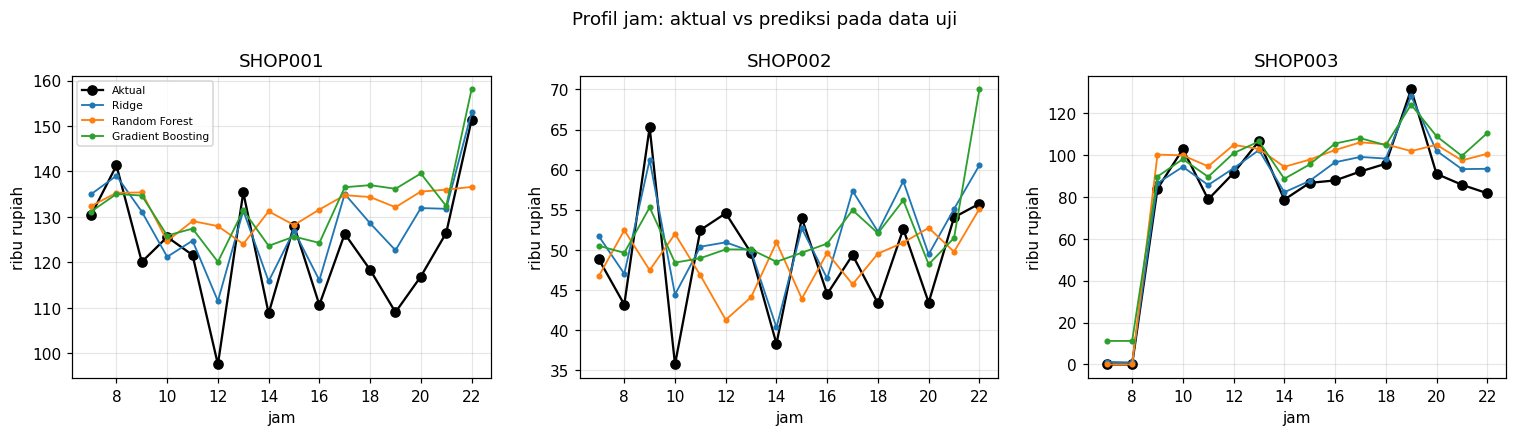

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=False)

scored_all = test.reset_index(drop=True).copy()

for ax, outlet in zip(axes, sorted(test.Outlet.unique())):
    mask = (scored_all.Outlet == outlet).to_numpy()
    group = scored_all[mask]
    actual_profile = group.groupby("Hour").net_sales.mean() / 1000
    ax.plot(actual_profile.index, actual_profile.values, marker="o", color="black", label="Aktual")
    for name in models:
        scored = group.copy()
        scored["prediction"] = predictions[name][mask]
        predicted_profile = scored.groupby("Hour").prediction.mean() / 1000
        ax.plot(predicted_profile.index, predicted_profile.values, marker=".", lw=1.2, label=name)
    ax.set_title(outlet)
    ax.set_xlabel("jam")
    ax.set_ylabel("ribu rupiah")

axes[0].legend(fontsize=7)
fig.suptitle("Profil jam: aktual vs prediksi pada data uji")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_2_profile_by_outlet.png", dpi=120)
plt.show()

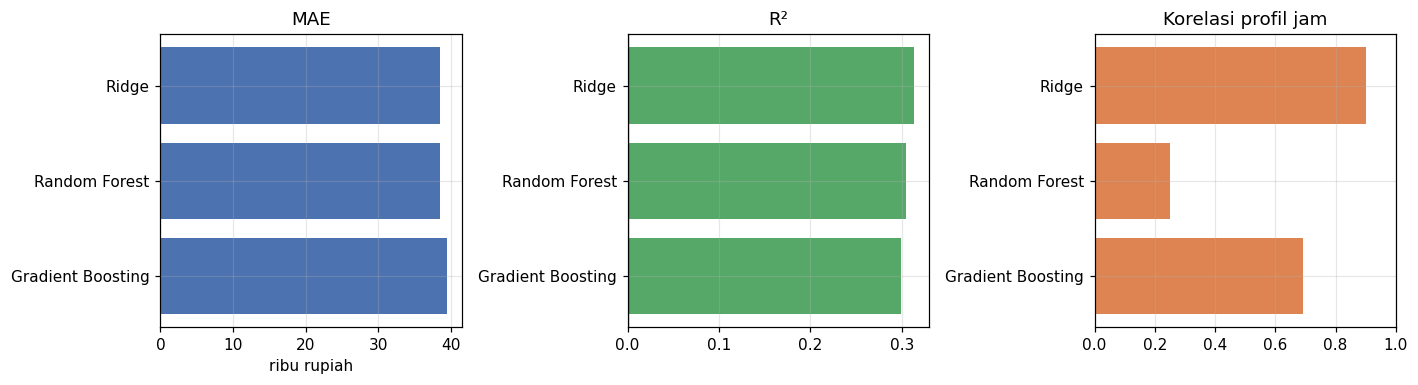

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

axes[0].barh(metrics.model, metrics.MAE / 1000, color="#4c72b0")
axes[0].set_title("MAE")
axes[0].set_xlabel("ribu rupiah")
axes[0].invert_yaxis()

axes[1].barh(metrics.model, metrics.R2, color="#55a868")
axes[1].set_title("R²")
axes[1].axvline(0, color="black", lw=0.8)
axes[1].invert_yaxis()

axes[2].barh(metrics.model, metrics.profil_corr, color="#dd8452")
axes[2].set_title("Korelasi profil jam")
axes[2].set_xlim(0, 1)
axes[2].invert_yaxis()

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_3_metrics.png", dpi=120)
plt.show()

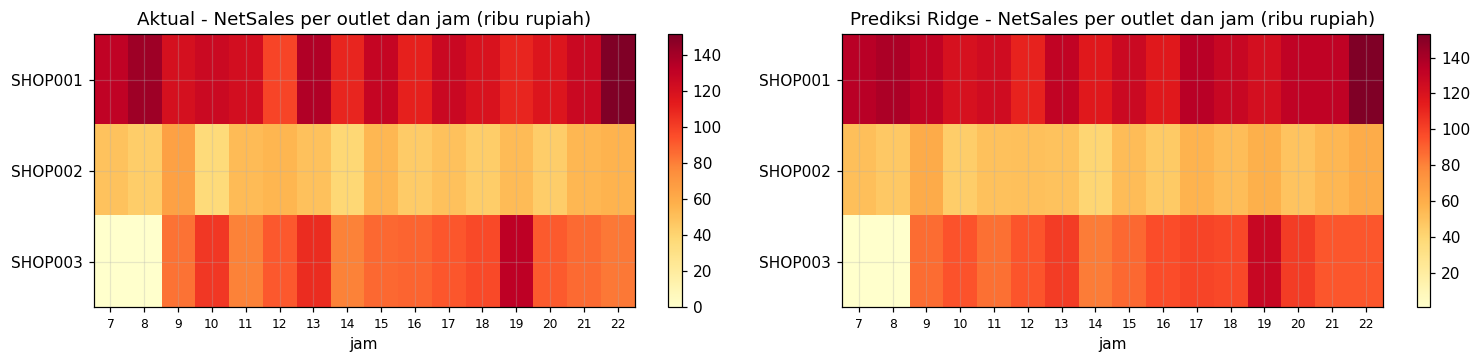

In [14]:
heatmap = test.copy()
heatmap["prediction"] = predictions[best_name]
actual_heat = heatmap.groupby(["Outlet", "Hour"]).net_sales.mean().unstack() / 1000
predicted_heat = heatmap.groupby(["Outlet", "Hour"]).prediction.mean().unstack() / 1000

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
for ax, table, title in [
    (axes[0], actual_heat, "Aktual"),
    (axes[1], predicted_heat, f"Prediksi {best_name}"),
]:
    image = ax.imshow(table.values, aspect="auto", cmap="YlOrRd")
    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels(table.index)
    ax.set_xticks(range(len(table.columns)))
    ax.set_xticklabels(table.columns, fontsize=8)
    ax.set_title(f"{title} - NetSales per outlet dan jam (ribu rupiah)")
    ax.set_xlabel("jam")
    fig.colorbar(image, ax=ax)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_4_heatmap.png", dpi=120)
plt.show()

## 9. Tabel jam tersibuk hasil prediksi

Ini keluaran utamanya: peringkat jam per outlet menurut model terbaik, beserta pangsa omzetnya.

In [15]:
best_prediction = predictions[best_name]
ranking_source = test[["Outlet", "Date", "Hour", "net_sales"]].copy()
ranking_source["prediction"] = best_prediction

peak_table = (
    ranking_source.groupby(["Outlet", "Hour"])
    .agg(predicted_net_sales=("prediction", "mean"), actual_net_sales=("net_sales", "mean"))
    .reset_index()
)
peak_table["predicted_share_%"] = peak_table.groupby("Outlet").predicted_net_sales.transform(
    lambda series: series / series.sum() * 100
)
peak_table["rank"] = peak_table.groupby("Outlet").predicted_net_sales.rank(ascending=False, method="min").astype(int)
peak_table = peak_table.sort_values(["Outlet", "rank"])

print(f"Peringkat jam menurut {best_name}:")
for outlet, group in peak_table.groupby("Outlet"):
    print()
    print(outlet)
    print(group.head(5)[["rank", "Hour", "predicted_net_sales", "actual_net_sales", "predicted_share_%"]].round(1).to_string(index=False))

Peringkat jam menurut Ridge:

SHOP001
 rank  Hour  predicted_net_sales  actual_net_sales  predicted_share_%
    1    22             152997.6          151319.2                7.4
    2     8             139053.6          141312.7                6.8
    3    17             135050.6          126287.0                6.6
    4     7             134995.8          130373.2                6.6
    5    20             131946.0          116891.9                6.4

SHOP002
 rank  Hour  predicted_net_sales  actual_net_sales  predicted_share_%
    1     9              61217.9           65283.1                7.4
    2    22              60559.5           55759.3                7.3
    3    19              58561.5           52606.2                7.1
    4    17              57360.1           49356.5                6.9
    5    21              55093.3           54054.1                6.7

SHOP003
 rank  Hour  predicted_net_sales  actual_net_sales  predicted_share_%
    1    19             128136.9  

## 10. Ekspor model terbaik ke pickle

Yang disimpan: model terbaik, daftar fitur, nama algoritma, dan riwayat 28 hari terakhir per
outlet x jam. Riwayat itu dipakai untuk membentuk fitur lag saat memprediksi hari berikutnya.

In [16]:
full_data = model_data.copy()

best_model = models[best_name]
best_model.fit(full_data[FEATURES].to_numpy(), full_data.net_sales.to_numpy())

history_columns = ["Outlet", "Date", "Hour", "net_sales"]
history = panel[history_columns].sort_values(["Outlet", "Hour", "Date"]).groupby(["Outlet", "Hour"]).tail(28)

bundle = {
    "name": best_name,
    "model": best_model,
    "feature_names": FEATURES,
    "outlets": sorted(panel.Outlet.unique().tolist()),
    "hour_range": [int(panel.Hour.min()), int(panel.Hour.max())],
    "history": history.reset_index(drop=True),
    "last_date": panel.Date.max(),
    "metrics": {record["model"]: {key: float(record[key]) for key in ["MAE", "RMSE", "R2", "peak@3", "profil_corr"]}
                for record in metrics.to_dict(orient="records")},
}

with open(MODEL_PATH, "wb") as file:
    pickle.dump(bundle, file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"algoritma disimpan : {best_name}")
print(f"MAE data uji       : Rp {metrics.loc[0, 'MAE']:,.0f}")
print(f"korelasi profil    : {metrics.loc[0, 'profil_corr']:.3f}")
print(f"lokasi berkas      : {MODEL_PATH}")
print(f"ukuran berkas      : {MODEL_PATH.stat().st_size / 1024:,.1f} KB")

algoritma disimpan : Ridge
MAE data uji       : Rp 38,419
korelasi profil    : 0.900
lokasi berkas      : ..\artifacts\peak_hour\model.pkl
ukuran berkas      : 49.0 KB


## 11. Menyimpan metadata

In [17]:
metadata = {
    "project": "MyVentory peak hour prediction",
    "target": "NetSales per jam per outlet",
    "unit": "rupiah per jam",
    "granularity": "jam x hari x outlet",
    "inputs": ["Time", "Date", "Outlet", "TotalItem", "NetSales"],
    "source": {
        "file": "data/Transactions.csv",
        "rows": int(len(transactions)),
        "outlets": sorted(transactions.Outlet.unique().tolist()),
    },
    "period": {
        "start": str(panel.Date.min().date()),
        "end": str(panel.Date.max().date()),
        "days": int(panel.Date.nunique()),
        "hours": sorted(int(hour) for hour in panel.Hour.unique()),
    },
    "panel_shape": {
        "rows": int(len(panel)),
        "closed_cells": int((panel.net_sales == 0).sum()),
        "closed_share": round(float((panel.net_sales == 0).mean()), 4),
    },
    "split": {
        "train_rows": int(len(train)),
        "test_rows": int(len(test)),
        "test_start": str(test.Date.min().date()),
        "test_end": str(test.Date.max().date()),
    },
    "features": FEATURES,
    "models": {
        record["model"]: {
            "MAE": round(float(record["MAE"]), 2),
            "RMSE": round(float(record["RMSE"]), 2),
            "R2": round(float(record["R2"]), 4),
            "peak@3": round(float(record["peak@3"]), 4),
            "profil_corr": round(float(record["profil_corr"]), 4),
        }
        for record in metrics.to_dict(orient="records")
    },
    "random_peak@3": round(3 / 16, 4),
    "peak_hour_by_outlet": {
        outlet: group.head(3).Hour.astype(int).tolist()
        for outlet, group in peak_table.groupby("Outlet")
    },
    "saved_model": {
        "file": MODEL_PATH.name,
        "algorithm": best_name,
        "last_date": str(panel.Date.max().date()),
        "mae_test": round(float(metrics.loc[0, "MAE"]), 2),
        "profil_corr": round(float(metrics.loc[0, "profil_corr"]), 4),
    },
    "note": (
        "Urutan jam tersibuk per hari sangat berubah-ubah sehingga skor peak@3 per hari mendekati acak. "
        "Model tetap berguna karena berhasil mereproduksi bentuk profil jam secara agregat "
        "(korelasi tinggi), dan pola itulah yang dipakai untuk perencanaan staf."
    ),
    "artifacts": [
        MODEL_PATH.name,
        METADATA_PATH.name,
        "peak_hour_table.csv",
        "hourly_forecast.csv",
        "peak_hour_metrics.csv",
        "fig_1_hourly_profile.png",
        "fig_2_profile_by_outlet.png",
        "fig_3_metrics.png",
        "fig_4_heatmap.png",
    ],
}

METADATA_PATH.write_text(json.dumps(metadata, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print("metadata tersimpan:", METADATA_PATH)

metadata tersimpan: ..\artifacts\peak_hour\metadata.json


## 12. Menyimpan tabel hasil

In [18]:
peak_table.round(4).to_csv(OUTPUT_DIR / "peak_hour_table.csv", index=False)
metrics.round(4).to_csv(OUTPUT_DIR / "peak_hour_metrics.csv", index=False)

hourly_forecast = test[["Outlet", "Date", "Hour", "net_sales"]].copy()
for name in models:
    hourly_forecast[name] = predictions[name]
hourly_forecast.round(2).to_csv(OUTPUT_DIR / "hourly_forecast.csv", index=False)

print(f"isi folder {OUTPUT_DIR.resolve()}:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {path.name:<32} {path.stat().st_size / 1024:>9.1f} KB")

isi folder C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\ML\artifacts\peak_hour:


  fig_1_hourly_profile.png              58.8 KB
  fig_2_profile_by_outlet.png          143.8 KB
  fig_3_metrics.png                     21.0 KB
  fig_4_heatmap.png                     38.5 KB
  hourly_forecast.csv                   78.1 KB
  metadata.json                          2.5 KB
  model.pkl                             49.0 KB
  peak_hour_metrics.csv                  0.2 KB
  peak_hour_table.csv                    2.1 KB


## 13. Verifikasi berkas pickle

Model dimuat ulang dari disk, lalu dipakai memprediksi jam-jam pada hari berikutnya (1 Oktober 2025).
Fitur lag dibentuk dari riwayat yang tersimpan di dalam berkas, bukan dari variabel notebook.

In [19]:
with open(MODEL_PATH, "rb") as file:
    loaded = pickle.load(file)

next_date = pd.Timestamp(loaded["last_date"]) + pd.Timedelta(days=1)
hours = list(range(loaded["hour_range"][0], loaded["hour_range"][1] + 1))

rows = []
for outlet in loaded["outlets"]:
    history = loaded["history"]
    history = history[history.Outlet == outlet].sort_values("Hour")

    for hour in hours:
        values = history[history.Hour == hour].sort_values("Date").net_sales.to_numpy()
        row = {
            "Hour": hour,
            "dow": next_date.dayofweek,
            "is_weekend": int(next_date.dayofweek >= 5),
            "month": next_date.month,
            "day_of_year": next_date.dayofyear,
            "hour_sin": np.sin(2 * np.pi * hour / 24),
            "hour_cos": np.cos(2 * np.pi * hour / 24),
            "outlet_code": int(outlet[-1]),
            "outlet_hour_mean": float(values.mean()),
            "lag_1d": float(values[-1]),
            "lag_7d": float(values[-7]),
            "roll_7": float(values[-7:].mean()),
            "roll_28": float(values.mean()),
        }
        rows.append({"Outlet": outlet, **row})

next_features = pd.DataFrame(rows)
next_prediction = loaded["model"].predict(next_features[loaded["feature_names"]].to_numpy())
next_features["predicted_net_sales"] = next_prediction
next_features["rank"] = next_features.groupby("Outlet").predicted_net_sales.rank(ascending=False, method="min").astype(int)

print("berkas        :", MODEL_PATH.name)
print("algoritma     :", loaded["name"], f"({type(loaded['model']).__name__})")
print("data terakhir :", pd.Timestamp(loaded["last_date"]).date())
print()
print(f"Prediksi jam ramai {next_date.date()}:")
for outlet, group in next_features.groupby("Outlet"):
    top = group.sort_values("predicted_net_sales", ascending=False).head(3)
    hours_text = ", ".join(f"{int(row.Hour):02d}:00" for row in top.itertuples())
    total = group.predicted_net_sales.sum()
    print(f"  {outlet}: {hours_text}  (perkiraan omzet sehari Rp {total:,.0f})")

print()
print("Seluruh jam untuk satu outlet, contoh SHOP001:")
contoh = next_features[next_features.Outlet == "SHOP001"].sort_values("predicted_net_sales", ascending=False)
print(contoh[["Outlet", "Hour", "predicted_net_sales", "rank"]].head(6).round(0).to_string(index=False))
print()
print("Catatan: peringkat jam untuk satu hari tertentu ikut berubah karena nilai lag harian")
print("turut dipakai. Yang stabil adalah bentuk profil jam secara keseluruhan, seperti")
print("ditunjukkan korelasi profil 0.900 pada tabel evaluasi.")

berkas        : model.pkl
algoritma     : Ridge (Pipeline)
data terakhir : 2025-09-30

Prediksi jam ramai 2025-10-01:
  SHOP001: 22:00, 19:00, 08:00  (perkiraan omzet sehari Rp 2,071,120)
  SHOP002: 22:00, 21:00, 09:00  (perkiraan omzet sehari Rp 766,609)
  SHOP003: 13:00, 10:00, 19:00  (perkiraan omzet sehari Rp 1,274,633)

Seluruh jam untuk satu outlet, contoh SHOP001:
 Outlet  Hour  predicted_net_sales  rank
SHOP001    22             171306.0     1
SHOP001    19             154326.0     2
SHOP001     8             152678.0     3
SHOP001    13             142434.0     4
SHOP001     7             138867.0     5
SHOP001    10             134620.0     6

Catatan: peringkat jam untuk satu hari tertentu ikut berubah karena nilai lag harian
turut dipakai. Yang stabil adalah bentuk profil jam secara keseluruhan, seperti
ditunjukkan korelasi profil 0.900 pada tabel evaluasi.


## 14. Ringkasan

In [20]:
print("RINGKASAN HASIL")
print("-" * 62)
print("target          : NetSales per jam per outlet")
print(f"panel           : {len(panel):,} sel ({panel.Date.nunique()} hari x 3 outlet x 16 jam)")
print(f"data uji        : {len(test):,} sel, {test.Date.nunique()} hari terakhir")
print()
print(metrics.round(3).to_string(index=False))
print()
print(f"model terbaik   : {best_name}")
print(f"MAE             : Rp {metrics.loc[0, 'MAE']:,.0f} per jam-outlet")
print(f"R2              : {metrics.loc[0, 'R2']:.3f}")
print(f"korelasi profil : {metrics.loc[0, 'profil_corr']:.3f}")
print()
print("Jam tersibuk menurut rata-rata data uji:")
for outlet in sorted(peak_table.Outlet.unique()):
    hours_text = ", ".join(str(int(hour)) for hour in peak_table[peak_table.Outlet == outlet].head(3).Hour)
    print(f"  {outlet}: jam {hours_text}")
print()
print("berkas keluaran:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("  ", path.name)

RINGKASAN HASIL
--------------------------------------------------------------
target          : NetSales per jam per outlet
panel           : 13,056 sel (272 hari x 3 outlet x 16 jam)
data uji        : 1,344 sel, 28 hari terakhir

            model       MAE      RMSE    R2  peak@3  profil_corr
            Ridge 38419.120 49477.149 0.314   0.210        0.900
    Random Forest 38520.001 49813.000 0.304   0.202        0.251
Gradient Boosting 39476.027 50015.082 0.299   0.246        0.692

model terbaik   : Ridge
MAE             : Rp 38,419 per jam-outlet
R2              : 0.314
korelasi profil : 0.900

Jam tersibuk menurut rata-rata data uji:
  SHOP001: jam 22, 8, 17
  SHOP002: jam 9, 22, 19
  SHOP003: jam 19, 13, 20

berkas keluaran:
   fig_1_hourly_profile.png
   fig_2_profile_by_outlet.png
   fig_3_metrics.png
   fig_4_heatmap.png
   hourly_forecast.csv
   metadata.json
   model.pkl
   peak_hour_metrics.csv
   peak_hour_table.csv


## Export model ke API (berversion)

Model disalin ke `API/artifacts/peak_hour/1.0.0/` sehingga versi lama tetap tersimpan dan bisa
dibandingkan. Versi juga ditulis ke `metadata.json` sebagai `model_version`.

In [21]:
import shutil

NOTEBOOK_NAME = "peak_hour_forecast"
NOTEBOOK_VERSION = "1.0.0"
API_DIR = Path("..").resolve().parent / "API" / "artifacts" / "peak_hour" / NOTEBOOK_VERSION
API_DIR.mkdir(parents=True, exist_ok=True)

api_metadata = json.loads((OUTPUT_DIR / "metadata.json").read_text(encoding="utf-8"))
api_metadata.update({
    "model_id": "peak_hour",
    "model_version": NOTEBOOK_VERSION,
    "source_notebook": NOTEBOOK_NAME,
})

shutil.copy2(OUTPUT_DIR / "model.pkl", API_DIR / "model.pkl")
(API_DIR / "metadata.json").write_text(
    json.dumps(api_metadata, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print(f"{NOTEBOOK_NAME} versi {NOTEBOOK_VERSION} diekspor ke:")
print(" ", API_DIR)
for path in sorted(API_DIR.iterdir()):
    print(f"   {path.name:<20} {path.stat().st_size / 1024:>9.1f} KB")

peak_hour_forecast versi 1.0.0 diekspor ke:
  C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\API\artifacts\peak_hour\1.0.0
   metadata.json              2.6 KB
   model.pkl                 49.0 KB
